# Практическая работа №8: Аналитические выводы, сравнение групп и интерпретация визуализаций
**Вариант 4**

Задания варианта:
1. Построить `crosstab` по `weekday` и `status`.
2. Посчитать доли по строкам.
3. Построить stacked bar chart.
4. Найти день с наибольшей долей `cancelled`.
5. Сформулировать бизнес-вывод.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Подготовка данных

In [2]:
orders_files = [
    "data/orders_2024_01.csv",
    "data/orders_2024_02.csv",
    "data/orders_2024_03.csv",
]

df_orders = pd.concat([pd.read_csv(f) for f in orders_files], ignore_index=True)
df_orders["order_datetime"] = pd.to_datetime(df_orders["order_datetime"])
df_orders["weekday"] = df_orders["order_datetime"].dt.day_name()

weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
df_orders["weekday"] = pd.Categorical(df_orders["weekday"], categories=weekday_order, ordered=True)

print(df_orders.head())

   order_id  user_id      order_datetime  product_id     price  quantity  \
0         1     1044 2024-01-03 18:39:26          26  14038.15         1   
1         2     1079 2024-01-03 17:45:43          16   9172.60         1   
2         3     1041 2024-01-06 22:46:38          25   9035.26         2   
3         4     1083 2024-01-08 21:03:51           9  15234.33         3   
4         5     1068 2024-01-03 23:26:53          24   4134.38         2   

     status    weekday  
0  refunded  Wednesday  
1      paid  Wednesday  
2      paid   Saturday  
3      paid     Monday  
4      paid  Wednesday  


## Задание 1. Crosstab по `weekday` и `status`

In [3]:
ct = pd.crosstab(df_orders["weekday"], df_orders["status"])

print(ct)

status     cancelled  paid  refunded
weekday                             
Monday           340  1680       105
Tuesday          299  1707       114
Wednesday        354  1702        99
Thursday         311  1830       115
Friday           284  1725        96
Saturday         315  1701       116
Sunday           309  1687       111


## Задание 2. Доли по строкам

In [4]:
status_share = pd.crosstab(df_orders["weekday"], df_orders["status"], normalize="index")

print(status_share.round(4))

status     cancelled    paid  refunded
weekday                               
Monday        0.1600  0.7906    0.0494
Tuesday       0.1410  0.8052    0.0538
Wednesday     0.1643  0.7898    0.0459
Thursday      0.1379  0.8112    0.0510
Friday        0.1349  0.8195    0.0456
Saturday      0.1477  0.7978    0.0544
Sunday        0.1467  0.8007    0.0527


## Задание 3. Stacked bar chart

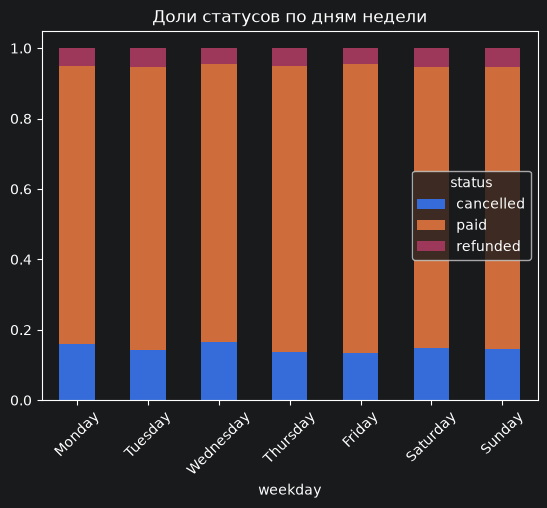

In [5]:
status_share.plot(kind="bar", stacked=True)
plt.title("Доли статусов по дням недели")
plt.xticks(rotation=45)
plt.show()

## Задание 4. День с наибольшей долей `cancelled`

In [6]:
max_day = status_share["cancelled"].idxmax()

print("День с наибольшей долей cancelled:", max_day)
print(f"Доля cancelled: {status_share.loc[max_day, 'cancelled'] * 100:.2f}%")

День с наибольшей долей cancelled: Wednesday
Доля cancelled: 16.43%


## Задание 5. Бизнес-вывод

Больше всего отмен в среду: 16,43% заказов. Близко к ней понедельник (16,00%), а меньше всего отмен в пятницу (13,49%). Доля оплаченных заказов во все дни держится на уровне 79–82%, доля возвратов — 4,6–5,4%. Для бизнеса это значит, что стоит проверить, почему в начале и середине недели заказы отменяют чаще: например, загрузку склада, сроки доставки или наличие товара в эти дни. Можно ввести дополнительное подтверждение заказов, оформленных в понедельник и среду.